In [1]:
import matplotlib.pyplot as plt
import scipy.optimize as opt
from scipy.signal import find_peaks

# zero field

In [2]:
def gaussian(x, G, m):
    return np.exp(-(x-m)**2/(2*G**2))
    
def ZF_four_gaussians(x, x02, A, G,e, a1,a2,a3,a4, c):
     return a1*gaussian(x,G,x02-A)+a2*gaussian(x,G,x02)+a3*gaussian(x,G,x02+e+A)+a4*gaussian(x,G,x02+e+2*A) + c

In [3]:
x = odmrlogic.odmr_plot_x
y = odmrlogic.odmr_plot_y[0]
y = y/np.max(y)
contrast = 1-np.min(y)

popt, pcov = opt.curve_fit(ZF_four_gaussians, x, y, p0 = [3.44e9, 70e6, 40e6, 10e6, -contrast/3, -contrast, -contrast, -contrast/3, 1 ])
x_fit = np.linspace(np.min(x), np.max(x), 1000)
fit = ZF_four_gaussians(x_fit, *popt )
print(popt)

[ 3.43092314e+09  5.81272552e+07  2.19717955e+07  3.70625961e+07
 -2.39448653e-03 -6.18714896e-03 -1.08433662e-02 -8.06679696e-03
  9.99271425e-01]


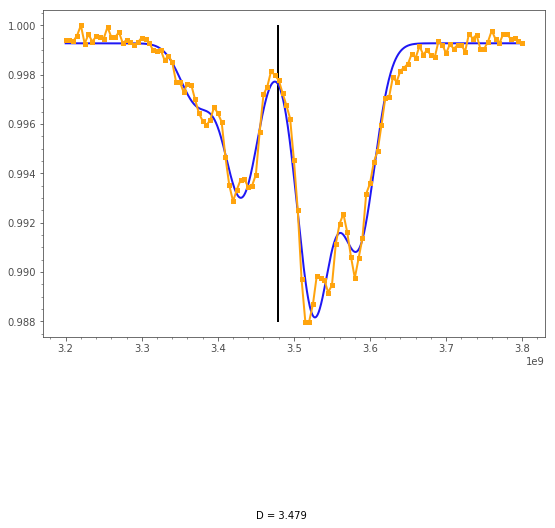

In [4]:
plt.plot(x_fit, fit, linestyle ='-', marker ='')
plt.plot(x, y)
plt.text(3.45e9, 0.98, 'D = ' + str(round((popt[0]+(popt[1]+popt[3])/2)*1e-9, 3)))
plt.vlines((popt[0]+(popt[1]+popt[3])/2), np.min(y), np.max(y))
plt.show()

# With field

In [45]:
def gaussian(x, G, m):
    return np.exp(-(x-m)**2/(2*G**2))
    
def four_gaussians(x, x02, A, G, a1,a2,a3,a4):
     return a1*gaussian(x,G,x02-A)+a2*gaussian(x,G,x02)+a3*gaussian(x,G,x02+A)+a4*gaussian(x,G,x02+2*A) 
    
def two_lines(x, x02, A, G, a1, a2, a3, a4, shift, a1_,a2_,a3_,a4_, c ):
    return four_gaussians(x, x02, A, G, a1,a2,a3,a4) + four_gaussians(x, x02+shift, A, G, a1_,a2_,a3_,a4_) + c

In [48]:
x = odmrlogic.odmr_plot_x
y = odmrlogic.odmr_plot_y[0]
y = y/np.percentile(y,95)
contrast = 1-np.min(y)
print(contrast)
bounds_l = [3.22e9, 66e6, 5e6, -0.2, -0.2, -0.2, -0.2, 0.3e9, -0.25, -0.6, -0.6, -0.4, 0.8 ]
bounds_u = [3.3e9, 68e6,110e6, -0.001, -0.0001, -0.0001, -0.0001,0.45e9, -0.0004, -0.0004, -0.0004, -0.0004, 1.2 ]


popt, pcov = opt.curve_fit(two_lines, x, y, p0 = [3.27e9, 66e6, 80e6, -contrast/4, -contrast, -contrast, -contrast/4,0.34e9, -contrast/4, -contrast, -contrast, -contrast/4 , 1 ], bounds = (bounds_l, bounds_u))
x_fit = np.linspace(np.min(x), np.max(x), 1000)
fit = two_lines(x_fit, *popt )
print(2*np.sqrt(np.log(2)*2)*popt[2])

0.01712109169517617
48403825.677329905


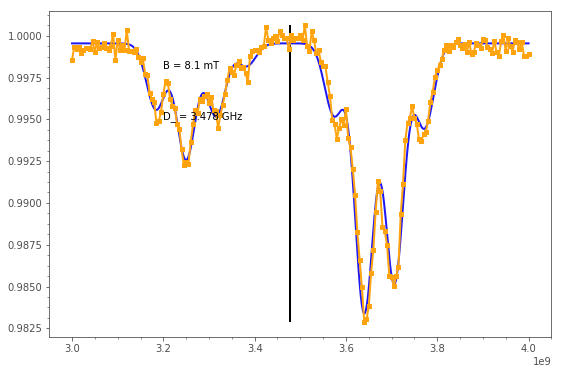

In [49]:
plt.plot(x_fit, fit, linestyle ='-', marker ='')
plt.plot(x, y)
peaks = find_peaks(-y, -0.94)[0]
plt.plot(x[peaks], y[peaks], linestyle ='', marker = 'd', ms = 10, color ='black')
plt.text(3.2e9, 0.998, 'B = ' + str(round(((popt[7]+popt[1])/(2*28e6)), 1)) + ' mT')
D = (2*popt[0]+popt[7]+popt[1])/2
plt.text(3.2e9, 0.995, 'D_ = ' + str(round(D*1e-9,4)) + ' GHz')
plt.vlines(D, np.min(y), np.max(y))
# plt.xlim(4.5e9,6e9)
# plt.xlim(1.5e9,2.5e9)
plt.show()

In [189]:
from scipy.signal import find_peaks
peaks = find_peaks(y)[0]
plt.plot(peaks, x[peaks], "x")

In [114]:
12*28

336

In [112]:
1/(20e6)

5e-08

In [51]:
y[peaks]

array([0.99942003, 1.00380656, 0.99946055, 1.00063063, 0.99776874,
       0.99764211, 0.99041396, 0.98619965, 0.98509542, 0.98256278,
       0.97312616, 0.96896757, 0.97296914, 0.97647431, 0.96532057,
       0.96975775, 0.97641859, 0.98360623, 0.98535881, 0.98867657,
       0.99656827, 0.99741924, 1.00444985, 0.99916676, 1.00211475,
       0.99906039, 1.00001266, 0.99168534, 0.99113323, 0.99018096,
       0.99040383, 0.98581975, 0.97501551, 0.98644278, 0.97697578,
       0.98822069, 0.99006446, 0.99298206, 0.99425851, 0.99815877,
       0.99746989, 1.00088389, 1.00337601, 0.99744457])

# Field Alignement 

In [ ]:
D_ref = 3.47e9
time_per_odmr = 5*60
stepper_step_per_step = 250
number_of_steps = int(8000/stepper_step_per_step)
delta_tab = np.zeros((number_of_steps, number_of steps))

In [ ]:
# fit_results_t1 = []
# fit_results_odmr = []
pulsedmeasurementlogic.toggle_pulsed_measurement(False)
time.sleep(2)
for i in range(number_of_steps):
    agilis_motor.move(channel=1, axis=1, number_of_steps=stepper_step_per_step)
    for j in range(number_of_steps):
        agilis_motor.move(channel=3, axis=1, number_of_steps=stepper_step_per_step)

        if kernellogic.stop_scripts:
                break
        pulsedmeasurementlogic.toggle_pulsed_measurement(False)
        pulsedmasterlogic.sample_ensemble('laser_on', with_load=True)
        time.sleep(2)
        pulsedmeasurementlogic.toggle_pulsed_measurement(True)
    
    
        time.sleep(1)
        refocus_poi()
    
        odmrlogic.start_odmr_scan()
     
        for _ in range(time_per_odmr):
            if kernellogic.stop_scripts:
                break
            time.sleep(1)

        odmrlogic.stop_odmr_scan()
    
        odmrlogic.do_fit('Two Lorentzian dips')
        time.sleep(0.1)
        central_frequency_0 = odmrlogic.fc.fit_list['Two Lorentzian dips']['parameters']['l0_center'].value
        central_frequency_1 = odmrlogic.fc.fit_list['Two Lorentzian dips']['parameters']['l1_center'].value
        D_eff = (central_frequency_0+central_frequency_1)/2
        delta = D_eff - D_ref
        delta_tab[i][j] = delta
    
        save.update_additional_parameters(delta = delta)
        odmrlogic.save_odmr_data()

        time.sleep(2)
        

In [2]:
print(np.min(delta_tab))

Parameters([('l0_amplitude', <Parameter 'l0_amplitude', value=-14587.287742241635 +/- 460, bounds=[-inf:-0.01]>), ('l0_center', <Parameter 'l0_center', value=3312650281.050601 +/- 1.94e+06, bounds=[2345000000.0:4605000000.0]>), ('l0_sigma', <Parameter 'l0_sigma', value=80211441.18423608 +/- 4.8e+06, bounds=[2500000.0:3000000000.0]>), ('offset', <Parameter 'offset', value=657499.9092653322 +/- 540, bounds=[-inf:inf]>), ('l1_amplitude', <Parameter 'l1_amplitude', value=-11522.703411027935 +/- 501, bounds=[-inf:-0.01]>), ('l1_center', <Parameter 'l1_center', value=3668137245.705142 +/- 2.9e+06, bounds=[2345000000.0:4605000000.0]>), ('l1_sigma', <Parameter 'l1_sigma', value=110179667.79758082 +/- 7.07e+06, bounds=[2500000.0:3000000000.0]>), ('l0_fwhm', <Parameter 'l0_fwhm', value=160422882.36847216 +/- 9.6e+06, bounds=[-inf:inf], expr='2*l0_sigma'>), ('l0_contrast', <Parameter 'l0_contrast', value=-2.2185992023239924 +/- 0.0687, bounds=[-inf:inf], expr='(l0_amplitude/offset)*100'>), ('l1_f

In [39]:
41-34.75

6.25

In [40]:
62.5*2

125.0

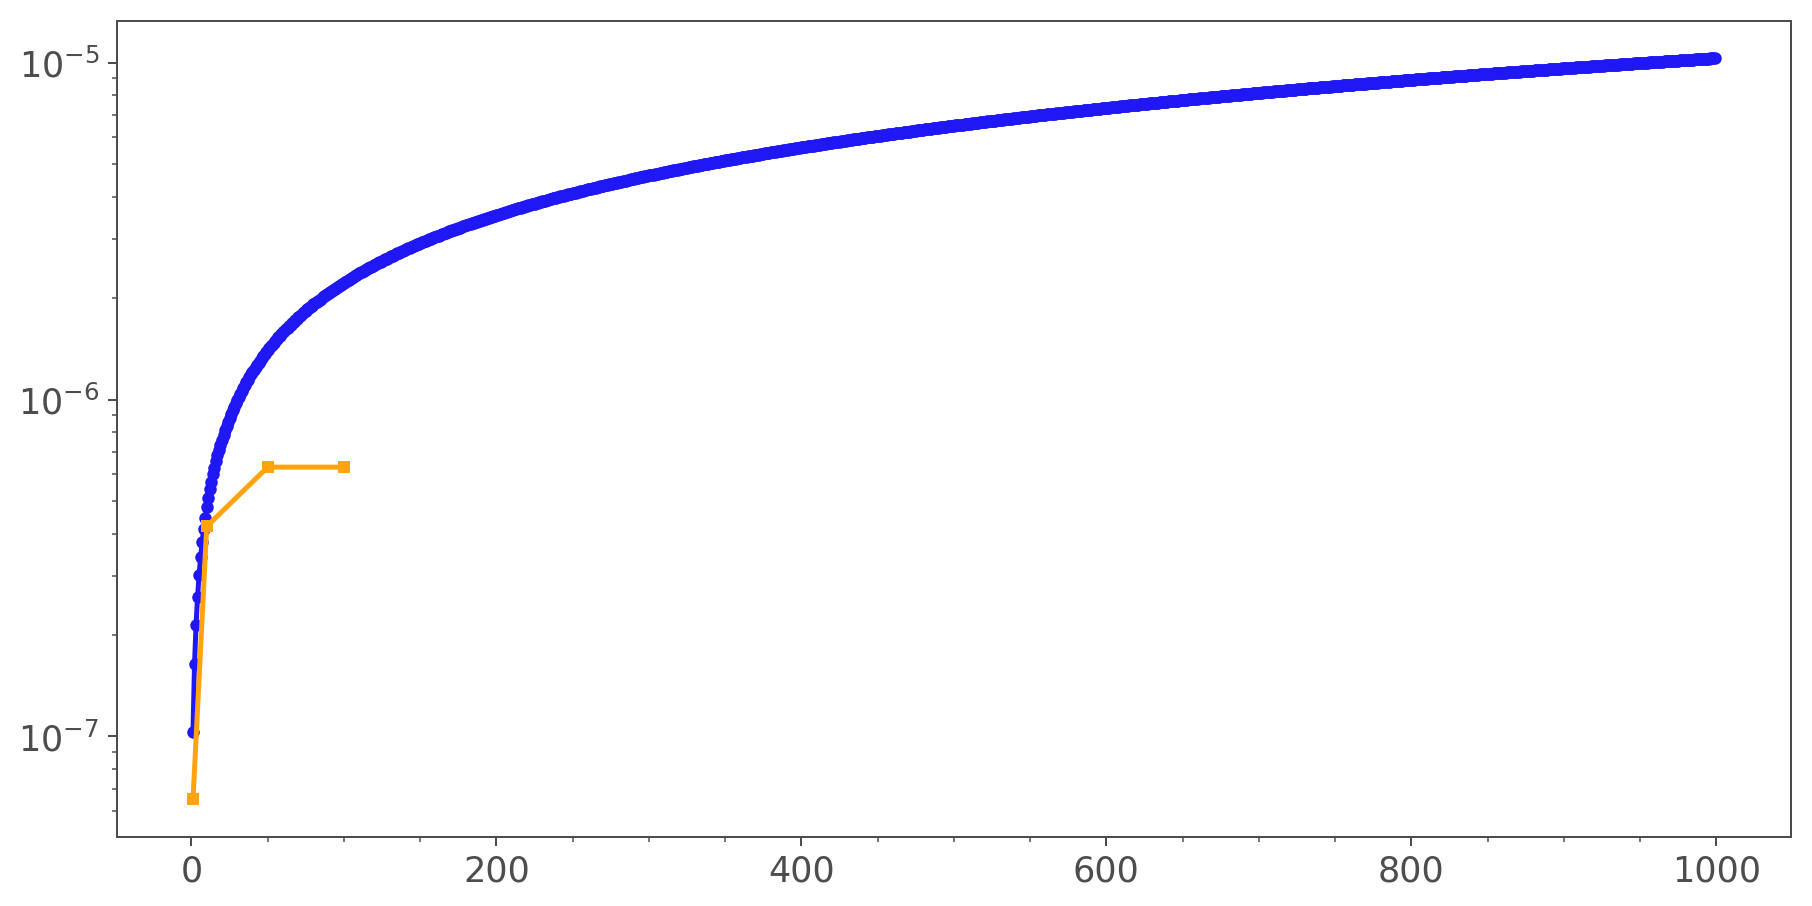

In [116]:
NN = np.arange(1,1000, 1)
plt.plot(NN, 65e-9*(2*NN)**(2/3))
plt.plot([1,10,50,100], [65e-9, 420e-9,630e-9, 630e-9])
plt.yscale('log')
plt.show()

In [34]:
160*50**(2/3)

2171.534093275925

In [ ]:
(3.47-2.56)/28

In [20]:
3.474/2

1.737

In [25]:
150*(1000)**(2/3)

14999.999999999996